In [1]:
import pandas as pd
import matplotlib.pyplot as plt

path = "../data/archive/US_Accidents_March23.csv"

df_head = pd.read_csv(path, nrows=1000)
print("Shape:", df_head.shape)
df_head.info()
df_head.head(3).T   # transposed: 46 columns are easier to read vertically

Shape: (1000, 46)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 46 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID                     1000 non-null   str    
 1   Source                 1000 non-null   str    
 2   Severity               1000 non-null   int64  
 3   Start_Time             1000 non-null   str    
 4   End_Time               1000 non-null   str    
 5   Start_Lat              1000 non-null   float64
 6   Start_Lng              1000 non-null   float64
 7   End_Lat                0 non-null      float64
 8   End_Lng                0 non-null      float64
 9   Distance(mi)           1000 non-null   float64
 10  Description            1000 non-null   str    
 11  Street                 1000 non-null   str    
 12  City                   1000 non-null   str    
 13  County                 1000 non-null   str    
 14  State                  1000 non-null   str    
 15

,0,1,2
ID,A-1,A-2,A-3
Source,Source2,Source2,Source2
Severity,3,2,2
Start_Time,2016-02-08 05:46:00,2016-02-08 06:07:59,2016-02-08 06:49:27
End_Time,2016-02-08 11:00:00,2016-02-08 06:37:59,2016-02-08 07:19:27
Start_Lat,39.865147,39.928059,39.063148
Start_Lng,-84.058723,-82.831184,-84.032608
End_Lat,NaN,NaN,NaN
End_Lng,NaN,NaN,NaN
Distance(mi),0.01,0.01,0.01


## Step 1.1 – First look at the data

The raw file contains about 7.7 million accidents and 46 columns, which is too large to load blindly
with 16 GB of RAM. We first read only the first 1,000 rows to understand the structure (types,
example values, missing values). This sample is only used for exploration: it is not necessarily
representative, so any figure derived from it is re-checked on a larger random sample later.

In [2]:
country = pd.read_csv(path, usecols=["Country"])["Country"]
print("Distinct values in 'Country':", country.nunique())

def agreement(a, b):
    """Share of rows where two columns have the same value (missing values ignored)."""
    sub = df_head[[a, b]].dropna()
    return (sub[a] == sub[b]).mean()

print(f"Sunrise_Sunset vs Civil_Twilight:           {agreement('Sunrise_Sunset', 'Civil_Twilight'):.3f}")
print(f"Nautical_Twilight vs Astronomical_Twilight: {agreement('Nautical_Twilight', 'Astronomical_Twilight'):.3f}")

Distinct values in 'Country': 1
Sunrise_Sunset vs Civil_Twilight:           0.932
Nautical_Twilight vs Astronomical_Twilight: 0.961


## Step 1.2 – Column selection (drop / test)

| Column | Decision | Reason |
|---|---|---|
| `ID` | drop | Identifier, no predictive information |
| `Description` | drop | Free text (no NLP in this project) and written after the accident |
| `Country` | drop | Constant: a single distinct value |
| `End_Lat`, `End_Lng`, `End_Time`, `Distance(mi)` | drop | Only known after the accident: data leakage |
| `Civil_Twilight`, `Nautical_Twilight` | drop | Redundant: they agree with `Sunrise_Sunset` (93.2 %) and `Astronomical_Twilight` (96.1 %). The two extremes are kept: together they distinguish day, twilight and full night |
| `Source` | filter, then drop | *(to be confirmed by the Source check)* Source 1 labels severity differently over time; we keep Source 2 only, so the column becomes constant |
| `Street`, `City`, `County`, `Zipcode` | drop | Redundant with `Start_Lat` / `Start_Lng`, and a very high number of distinct values |
| `Timezone` | drop | Redundant with longitude and `State` |
| `Airport_Code` | drop | Identifies a weather station, not a property of the accident |



## Step 1.3 – Columns to keep

| Group | Columns | Decision |
|---|---|---|
| Target | `Severity` | Binary: `Severity >= 3` → 1 (see distribution) |
| Time | `Start_Time` | Keep; hour, weekday and month are extracted later |
| Position | `Start_Lat`, `Start_Lng`, `State` | Keep. `State` is the only administrative column kept: lowest cardinality (~49 values) |
| Weather (numerical) | `Temperature(F)`, `Wind_Chill(F)`, `Humidity(%)`, `Pressure(in)`, `Visibility(mi)`, `Wind_Speed(mph)`, `Precipitation(in)` | Keep (missing values handled in Step 1.4) |
| Weather (categorical) | `Wind_Direction`, `Weather_Condition` | Keep |
| Infrastructure | `Amenity`, `Bump`, `Crossing`, `Give_Way`, `Junction`, `No_Exit`, `Railway`, `Roundabout`, `Station`, `Stop`, `Traffic_Calming`, `Traffic_Signal`, `Turning_Loop` | Keep |
| Light | `Sunrise_Sunset`, `Astronomical_Twilight` | Keep |

Missing Weather_Timestamp: 0.011
Share measured after Start_Time: 0.506
More than 0.5 h after Start_Time: 0.0314
More than 1 h after Start_Time: 0.0191
More than 2 h after Start_Time: 0.0150
More than 2 h before Start_Time: 0.0083


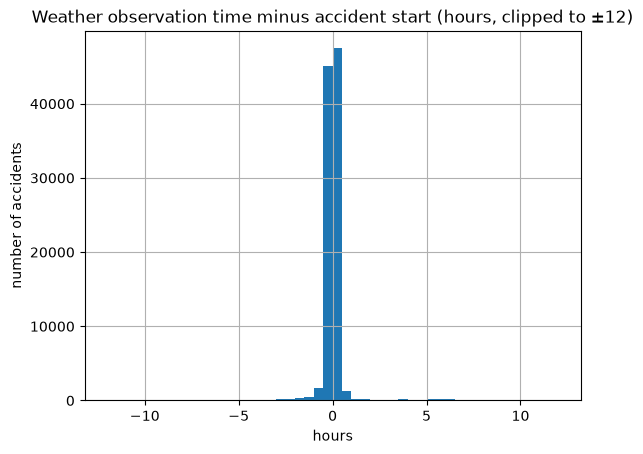

In [3]:
t = pd.read_csv(path, usecols=["Start_Time", "Weather_Timestamp"], nrows=100_000)
for col in t.columns:
    t[col] = pd.to_datetime(t[col], format="mixed", errors="coerce")

# positive = weather measured AFTER the accident started
t["delta_h"] = (t["Weather_Timestamp"] - t["Start_Time"]).dt.total_seconds() / 3600

print("Missing Weather_Timestamp:", t["Weather_Timestamp"].isna().mean().round(3))
print("Share measured after Start_Time:", (t["delta_h"] > 0).mean().round(3))
for h in [0.5, 1, 2]:
    print(f"More than {h} h after Start_Time: {(t['delta_h'] > h).mean():.4f}")
print(f"More than 2 h before Start_Time: {(t['delta_h'] < -2).mean():.4f}")

t["delta_h"].clip(-12, 12).hist(bins=48)
plt.title("Weather observation time minus accident start (hours, clipped to ±12)")
plt.xlabel("hours"); plt.ylabel("number of accidents")
plt.show()

### – Weather timestamp check

Weather observations are matched to the nearest station reading, so about half of them are
taken slightly after `Start_Time` (50.6 %): this is expected, not leakage. The gap is small for
most rows, but 0.72 % of observations (measured on the full Source 2) are more than 2 hours away from the
accident start. We keep these rows but set their weather values to missing,
because such observations do not describe the conditions at the time of the accident.
`Weather_Timestamp` is then dropped.

Rows: 7728394 | unreadable dates: 0

--- Rows per year and source ---
Source  Source2  Source3  Source1
year                             
2016     279666     1595   129560
2017     539528     7863   170702
2018     714373    11292   167761
2019     672608    19326   262369
2020     448305    21939   708669
2021     431482    18603  1113668
2022     219411    16771  1526270
2023          0        0   246633

--- Share of Severity >= 3 per year and source ---
Source  Source2  Source3  Source1
year                             
2016      0.368    0.475    0.284
2017      0.364    0.472    0.323
2018      0.360    0.486    0.334
2019      0.303    0.363    0.210
2020      0.306    0.297    0.102
2021      0.343    0.195    0.024
2022      0.345    0.225    0.027
2023        NaN      NaN    0.029

--- First and last accident per source ---
                         min                  max
Source                                           
Source2  2016-02-08 05:46:00  2022-09-08 17:56:22
Sour

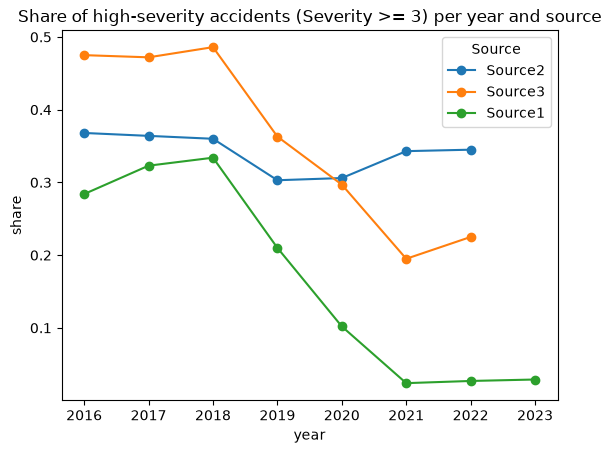

In [4]:
src = pd.read_csv(
    path,
    usecols=["Source", "Start_Time", "Severity"],
    dtype={"Source": "category", "Severity": "int8"},
)

# Dates are ISO strings ("2019-03-27 14:05:00"): the first 4 characters are the year.
# Much faster than parsing 7.7M dates, and ISO strings sort correctly as text.
src["year"] = pd.to_numeric(src["Start_Time"].str[:4], errors="coerce").astype("Int16")
src["high"] = src["Severity"] >= 3
print("Rows:", len(src), "| unreadable dates:", src["year"].isna().sum())

print("\n--- Rows per year and source ---")
print(pd.crosstab(src["year"], src["Source"]))

print("\n--- Share of Severity >= 3 per year and source ---")
share = src.pivot_table(index="year", columns="Source", values="high",
                        aggfunc="mean", observed=True).round(3)
print(share)

print("\n--- First and last accident per source ---")
print(src.groupby("Source", observed=True)["Start_Time"].agg(["min", "max"]))

print("\n--- Severity distribution (all rows / per source) ---")
print(src["Severity"].value_counts(normalize=True).sort_index().round(4))
print(pd.crosstab(src["Source"], src["Severity"], normalize="index").round(4))

share.plot(marker="o")
plt.title("Share of high-severity accidents (Severity >= 3) per year and source")
plt.ylabel("share"); plt.show()

### Step 1.2c – Source check

The accidents come from three providers. Their labelling of `Severity` is not comparable over time:

- **Source 1** (7.7M rows overall, mostly after 2020): the share of `Severity >= 3` falls from
  about 33 % (2018) to 2.4 % (2021), while its volume is multiplied by 10. This reflects a change
  in labelling, not in reality.
- **Source 2**: stable share of `Severity >= 3` (30–37 %) over 2016–2022, with regular volumes.
- **Source 3**: too few rows (under 22,000 per year) and an unstable share.

**Decision:** we keep Source 2 only: 3.3M accidents, from 2016-02-08 to 2022-09-08.
Mixing providers would let the model learn the provider rather than the accident.
`Source` is then dropped (constant). Source 2 has no data in 2023, and 2016 and 2022 are partial
years, which constrains the train/validation/test split.

### Step 2.1 – Chronological split

Source 2 covers 2016-02-08 to 2022-09-08. We split by time to avoid training on the future:

| Set | Period | Rows | Share | `Severity >= 3` |
|---|---|---|---|---|
| Train | 2016-02-08 → 2020-09-08 | 2,499,127 | 75.6 % | 34.0 % |
| Validation | 2020-09-09 → 2021-09-08 | 444,935 | 13.5 % | 33.7 % |
| Test | 2021-09-09 → 2022-09-08 | 361,311 | 10.9 % | 34.0 % |

Validation and test each cover exactly one full year, so every season is represented. The share of
high-severity accidents is nearly identical across the three sets, which makes scores comparable.

In [5]:
import numpy as np
import pandas as pd

# ---------------- configuration ----------------
SEED = 42
VAL_START, TEST_START = "2020-09-09", "2021-09-09"   # train < VAL_START <= validation < TEST_START <= test
TARGET_ROWS = {"train": 500_000, "validation": 150_000, "test": 150_000}
FULL_ROWS   = {"train": 2_499_127, "validation": 444_935, "test": 361_311}   # Source 2 rows per set (split check)
FRAC = {k: TARGET_ROWS[k] / FULL_ROWS[k] for k in TARGET_ROWS}
MAX_GAP_H = 2          # weather observation farther than 2 h from Start_Time -> set to missing

WEATHER_NUM = ["Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)",
               "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
WEATHER_CAT = ["Wind_Direction", "Weather_Condition"]
POI = ["Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit", "Railway",
       "Roundabout", "Station", "Stop", "Traffic_Calming", "Traffic_Signal", "Turning_Loop"]
LIGHT = ["Sunrise_Sunset", "Astronomical_Twilight"]
CAT_COLS = ["State"] + WEATHER_CAT + LIGHT

USECOLS = (["Source", "Severity", "Start_Time", "Weather_Timestamp", "Start_Lat", "Start_Lng", "State"]
           + WEATHER_NUM + WEATHER_CAT + POI + LIGHT)
DTYPES = {"Source": "category", "Severity": "int8", "Start_Lat": "float32", "Start_Lng": "float32",
          **{c: "float32" for c in WEATHER_NUM}, **{c: "bool" for c in POI}}

def to_dt(s):
    """ISO string -> datetime (first 19 characters = 'YYYY-MM-DD HH:MM:SS')."""
    return pd.to_datetime(s.str[:19], format="%Y-%m-%d %H:%M:%S", errors="coerce")

# ---------------- single pass over the file, chunk by chunk ----------------
pieces, seen, masked_rows, bad_dates = [], 0, 0, 0
for i, chunk in enumerate(pd.read_csv(path, usecols=USECOLS, dtype=DTYPES, chunksize=200_000)):
    chunk = chunk[chunk["Source"] == "Source2"].drop(columns="Source")      # 1. keep Source 2 only
    if chunk.empty:
        continue

    start = to_dt(chunk["Start_Time"])                                      # 2. weather rule
    gap_h = (to_dt(chunk["Weather_Timestamp"]) - start).dt.total_seconds() / 3600
    too_far = gap_h.abs() > MAX_GAP_H
    chunk.loc[too_far, WEATHER_NUM + WEATHER_CAT] = np.nan
    seen += len(chunk); masked_rows += int(too_far.sum()); bad_dates += int(start.isna().sum())

    day = chunk["Start_Time"].str[:10]                                      # 3. chronological split
    chunk["split"] = np.select([day >= TEST_START, day >= VAL_START], ["test", "validation"], "train")
    chunk["Start_Time"] = start
    chunk["_year"] = start.dt.year
    chunk["_high"] = chunk["Severity"] >= 3
    chunk = chunk.drop(columns="Weather_Timestamp")                         # only needed for the check

    for name, part in chunk.groupby("split"):                               # 4. stratified sampling
        pieces.append(part.groupby(["_year", "_high"], group_keys=False)    #    same fraction in every
                          .sample(frac=FRAC[name], random_state=SEED + i))  #    (year x class) group

sample = pd.concat(pieces, ignore_index=True).drop(columns=["_year", "_high"])
for c in CAT_COLS:
    sample[c] = sample[c].astype("category")
data = {k: sample[sample["split"] == k].drop(columns="split").reset_index(drop=True)
        for k in ["train", "validation", "test"]}

print(f"Source 2 rows read: {seen:,} | weather masked (> {MAX_GAP_H} h): {masked_rows:,} "
      f"({masked_rows/seen:.2%}) | unreadable dates: {bad_dates}")
for k, d in data.items():
    print(f"{k:11s} rows={len(d):>8,}  Severity>=3: {(d['Severity'] >= 3).mean():.3f}  "
          f"{d['Start_Time'].min().date()} -> {d['Start_Time'].max().date()}")

Source 2 rows read: 3,305,373 | weather masked (> 2 h): 23,859 (0.72%) | unreadable dates: 0
train       rows= 499,998  Severity>=3: 0.340  2016-02-08 -> 2020-09-08
validation  rows= 150,001  Severity>=3: 0.337  2020-09-09 -> 2021-09-08
test        rows= 150,001  Severity>=3: 0.340  2021-09-09 -> 2022-09-08


### Step 2.2 – Loading, filtering and sampling

The full file is read in a single pass, in chunks of 200,000 rows, so it never has to fit in memory.
For each chunk we: (1) keep Source 2 only, (2) set weather values to missing when the observation is
more than 2 hours away from `Start_Time`, (3) assign the chronological split, (4) draw a random
sample with the **same fraction in every (year × class) group**, with a fixed seed so every teammate
gets exactly the same rows.

| Set | Rows | `Severity >= 3` | Period |
|---|---|---|---|
| Train | 499,998 | 34.0 % | 2016-02-08 → 2020-09-08 |
| Validation | 150,001 | 33.7 % | 2020-09-09 → 2021-09-08 |
| Test | 150,001 | 34.0 % | 2021-09-09 → 2022-09-08 |

The share of high-severity accidents is unchanged by the sampling (34.0 % in the full train set), and
we do not rebalance the classes: validation and test must reflect reality. On the full Source 2,
0.72 % of the weather observations were more than 2 hours away from the accident and were set to
missing. Only the columns we decided to keep are loaded, with compact types (`float32`, `bool`,
`category`).

In [6]:
X, y = {}, {}
for name, d in data.items():
    y[name] = (d["Severity"] >= 3).astype("int8").rename("y")   # 1 = high impact (level 3 or 4)
    X[name] = d.drop(columns="Severity")                        # the target must never stay in the features

# class balance in each set
balance = pd.DataFrame({
    name: {"rows": len(t), "y=1": int(t.sum()), "y=0": int((t == 0).sum()), "share y=1": t.mean()}
    for name, t in y.items()
}).T
balance["share y=1"] = balance["share y=1"].round(4)
print(balance)

# what the binary target hides: the original 4 levels
levels = pd.DataFrame({n: d["Severity"].value_counts(normalize=True).sort_index()
                       for n, d in data.items()}).round(4)
print("\nShare of each original level:\n", levels)
for n, d in data.items():
    print(f"{n:11s} level 3 represents {(d['Severity'] == 3).sum() / (d['Severity'] >= 3).sum():.1%} of the positives")

assert all("Severity" not in X[n].columns for n in X)            # safety check

                rows       y=1       y=0  share y=1
train       499998.0  169777.0  330221.0     0.3396
validation  150001.0   50532.0   99469.0     0.3369
test        150001.0   51004.0   98997.0     0.3400

Share of each original level:
            train  validation    test
Severity                            
1         0.0004      0.0003  0.0943
2         0.6601      0.6628  0.5657
3         0.3366      0.3267  0.3343
4         0.0030      0.0101  0.0058
train       level 3 represents 99.1% of the positives
validation  level 3 represents 97.0% of the positives
test        level 3 represents 98.3% of the positives


### Step 3 – Target

The target is binary: `y = 1` if `Severity >= 3` (high impact on traffic), `y = 0` otherwise.
`Severity` measures the impact on traffic, not the seriousness of injuries. This threshold is a
choice of the study, fixed before looking at any model score, and not changed afterwards to improve results.
`Severity` is removed from the features to avoid leakage.

| Set | Rows | y = 1 | y = 0 | Share of y = 1 |
|---|---|---|---|---|
| Train | ... | ... | ... | ...% |
| Validation | ... | ... | ... | ...% |
| Test | ... | ... | ... | ...% |

The classes are moderately imbalanced (about one third positives) and the share is the same in the
three sets. We do **not** rebalance the data: validation and test must reflect reality, and we will
use metrics suited to imbalance (F1, recall, precision, PR-AUC) instead of accuracy alone.
**Limit:** in Source 2, level 4 is only about 1.3 % of the positives, so the model mostly separates
level 3 from level 2 and tells us almost nothing about level 4.

(499998, 31) | Start_Time still in X: False


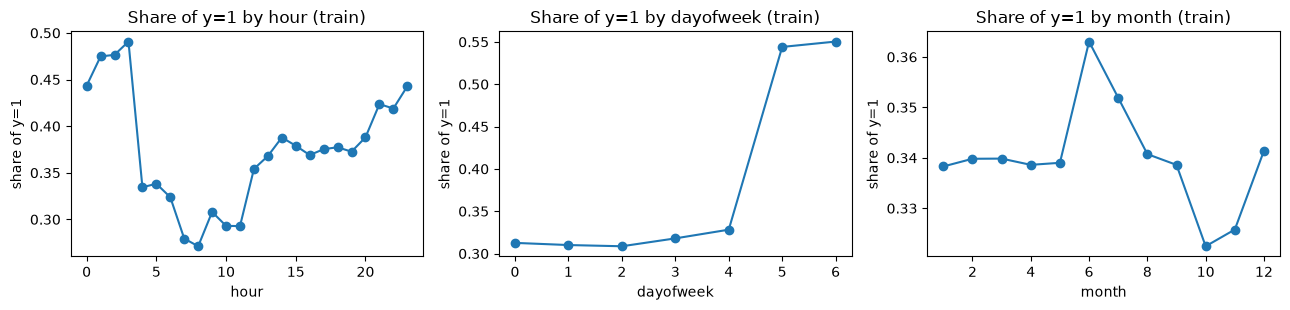

In [7]:
start_time = {}   # kept aside for analysis only (e.g. score per month); never given to a model
for name, d in X.items():
    t = d["Start_Time"]
    start_time[name] = t.copy()
    d["hour"] = t.dt.hour.astype("int8")                    # 0-23, local time
    d["dayofweek"] = t.dt.dayofweek.astype("int8")          # 0 = Monday ... 6 = Sunday
    d["month"] = t.dt.month.astype("int8")                  # 1-12
    d["is_weekend"] = t.dt.dayofweek >= 5                   # bool
    X[name] = d.drop(columns="Start_Time")

print(X["train"].shape, "| Start_Time still in X:", "Start_Time" in X["train"].columns)

# do these features carry a signal? (train only)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, col in zip(ax, ["hour", "dayofweek", "month"]):
    y["train"].groupby(X["train"][col]).mean().plot(ax=a, marker="o")
    a.set_title(f"Share of y=1 by {col} (train)"); a.set_ylabel("share of y=1")
plt.tight_layout(); plt.show()

### Step 4 – Time features

We extract `hour` (0–23, local time), `dayofweek` (0 = Monday), `month` (1–12) and `is_weekend` from
`Start_Time`, then remove `Start_Time` from the features. We do not use the year: validation and test
cover years the model never saw during training, so a `year` feature could not generalise.
The original timestamp is kept aside (`start_time`) only to analyse scores by month later.

On the training set, the share of high-severity accidents varies strongly with the hour
(27 % at 8 am to 49 % at 3 am) and the day (31 % on Wednesday, 55 % on Sunday; 32 % on weekdays vs
55 % on weekends), and only weakly with the month (32 % to 36 %). A possible explanation is lower
traffic at night and on weekends, but our data cannot confirm it.
Cyclic encoding (sin/cos) was not used: tree-based models do not need it.

In [8]:
# % of missing values per column and per set (only columns with at least one NaN)
miss = pd.DataFrame({k: d.isna().mean() * 100 for k, d in X.items()}).round(2)
print(miss[(miss > 0).any(axis=1)].sort_values("train", ascending=False))

# number of missing values per row (train)
print("\nMissing values per row (train):")
print(X["train"].isna().sum(axis=1).value_counts().sort_index())

                       train  validation  test
Precipitation(in)      61.13        4.54  3.53
Wind_Chill(F)          57.20        3.15  2.74
Wind_Speed(mph)        14.19        2.95  2.47
Visibility(mi)          2.65        2.67  2.26
Weather_Condition       2.64        2.63  2.12
Humidity(%)             2.44        2.78  2.31
Temperature(F)          2.34        2.64  2.18
Wind_Direction          2.16        2.95  2.47
Pressure(in)            2.11        2.46  1.94
Sunrise_Sunset          0.00        0.00  0.41
Astronomical_Twilight   0.00        0.00  0.41

Missing values per row (train):
0    164014
1     72744
2    193198
3     56520
4      1648
5      1561
6       111
7       287
8       634
9      9281
Name: count, dtype: int64


### Step 5.1 – Where are the missing values?

Only weather and light columns contain missing values. In the training set, `Precipitation(in)`
(61 %), `Wind_Chill(F)` (57 %) and `Wind_Speed(mph)` (14 %) are the most affected; the other weather
columns have about 2–3 %. In validation and test they are almost always present (3–5 %).
This is not random: these columns were barely recorded before 2019 (about 87–91 % missing in
2016–2018, 24 % in 2019, 4 % in 2020), so the missingness reflects a change in data collection.
Most rows have 0 to 3 missing values (typically `Precipitation`, `Wind_Chill`, `Wind_Speed`);
9,281 train rows have no weather at all.

In [9]:
X_all = {k: X[k].copy() for k in X}
y_all = {k: y[k].copy() for k in y}
n_nan = {k: X[k].isna().sum(axis=1) for k in X}      # missing values per row


In [10]:
MAX_NAN = 4

for k in X:
    keep = X[k].isna().sum(axis=1) <= MAX_NAN
    X[k], y[k], start_time[k] = (X[k][keep].reset_index(drop=True),
                                  y[k][keep].reset_index(drop=True),
                                  start_time[k][keep].reset_index(drop=True))
    print(f"{k:11s} dropped {(~keep).sum():>6,} rows -> {len(X[k]):>8,} rows left | share y=1: {y[k].mean():.3f}")

train       dropped 11,874 rows ->  488,124 rows left | share y=1: 0.338
validation  dropped  3,682 rows ->  146,319 rows left | share y=1: 0.336
test        dropped  2,920 rows ->  147,081 rows left | share y=1: 0.339


### Step 5.2 – Rows with too many missing values

We drop rows with more than 4 missing values, i.e. more than half of the 9 weather columns: such rows
carry almost no weather information, and imputing them would mean inventing most of the row. The same
fixed rule is applied to the three sets, and it was chosen from the training data only.

| Set | Rows dropped | Removed | Rows left | `Severity >= 3` |
|---|---|---|---|---|
| Train | 11,874 | 2.4 % | 488,124 | 33.8 % |
| Validation | 3,682 | 2.5 % | 146,319 | 33.6 % |
| Test | 2,920 | 1.9 % | 147,081 | 33.9 % |

Fewer than 2.5 % of the rows are removed in each set, so the sample sizes stay close to the targets
(500,000 / 150,000 / 150,000). The share of high-severity accidents moves by at most 0.2 points
(34.0 % → 33.8 % in train), so the class balance is preserved.

In [11]:
num_cols = WEATHER_NUM
cat_cols = list(X["train"].select_dtypes("category").columns)

fill = {c: X["train"][c].median() for c in num_cols}               # median of the TRAIN set
fill.update({c: X["train"][c].mode()[0] for c in cat_cols})        # most frequent value of the TRAIN set
print(fill)                                                        # Precipitation median should be 0.0

for k in X:
    d = X[k]
    d["Temperature(F)"] = d["Temperature(F)"].fillna(fill["Temperature(F)"])
    d["Wind_Chill(F)"] = d["Wind_Chill(F)"].fillna(d["Temperature(F)"])   # no wind-chill effect -> same as air temperature
    X[k] = d.fillna(fill)

assert all(X[k].isna().sum().sum() == 0 for k in X)
print({k: X[k].shape for k in X})

{'Temperature(F)': np.float32(64.9), 'Wind_Chill(F)': np.float32(58.0), 'Humidity(%)': np.float32(69.0), 'Pressure(in)': np.float32(29.96), 'Visibility(mi)': np.float32(10.0), 'Wind_Speed(mph)': np.float32(7.0), 'Precipitation(in)': np.float32(0.0), 'State': 'CA', 'Wind_Direction': 'Calm', 'Weather_Condition': 'Clear', 'Sunrise_Sunset': 'Day', 'Astronomical_Twilight': 'Day'}
{'train': (488124, 31), 'validation': (146319, 31), 'test': (147081, 31)}


### Step 5.3 – Filling the remaining missing values

All remaining gaps are filled with values **learned on the train set only** and then applied unchanged to validation and test, so no information from the future leaks into the training statistics.

- **Numeric weather columns: median.** The median is not affected by extreme values (wind speed, visibility, precipitation have long tails), so it is safer than the mean.
- **Categorical columns: most frequent value (mode).** This gives State = CA, Wind_Direction = Calm, Weather_Condition = Clear, Sunrise_Sunset = Day, Astronomical_Twilight = Day.
- **Precipitation: median = 0.0 in.** It is a sensible fill, since most observations are dry.
- **Wind_Chill: filled from Temperature, not from its own median.** Wind chill is close to the air temperature when the wind is light, so a row's own temperature is a better guess than a global value (58 F against a median temperature of 64.9 F). The temperature is filled first, so this fallback never uses a missing value.

Rejected alternatives:
- Dropping every row with a missing value would remove far too much data.
- Adding "is missing" indicator columns would mostly encode the year, since Precipitation and Wind_Chill were barely recorded before 2019.
- Fitting the fill values on all three sets together would be leakage.

Result: no missing value is left in any set. Final shapes (rows, columns): train (488,124, 31), validation (146,319, 31), test (147,081, 31). Tree models such as HistGradientBoosting handle NaN natively, so this imputation matters mainly for linear models and neural networks.

In [12]:
for c in ["State", "Wind_Direction", "Weather_Condition", "Sunrise_Sunset", "Astronomical_Twilight"]:
    print(f"{c:22s} {X['train'][c].nunique():>4} levels in train")

print(X["train"]["Weather_Condition"].value_counts(normalize=True).head(15).round(3))

State                    49 levels in train
Wind_Direction           24 levels in train
Weather_Condition        98 levels in train
Sunrise_Sunset            2 levels in train
Astronomical_Twilight     2 levels in train
Weather_Condition
Clear               0.255
Mostly Cloudy       0.145
Fair                0.140
Overcast            0.118
Partly Cloudy       0.100
Scattered Clouds    0.064
Cloudy              0.054
Light Rain          0.050
Light Snow          0.013
Rain                0.012
Haze                0.010
Fog                 0.009
Heavy Rain          0.004
Light Drizzle       0.004
Fair / Windy        0.002
Name: proportion, dtype: float64


In [13]:
TOP = X["train"]["Weather_Condition"].value_counts().head(15).index   # learned on train only
WIND_FIX = {"CALM": "Calm", "East": "E", "North": "N", "South": "S", "West": "W", "VAR": "Variable"}

encoded = {}
for k in X:
    d = X[k].copy()
    bool_cols = d.select_dtypes("bool").columns
    d[bool_cols] = d[bool_cols].astype("int8")                          # booleans -> 0/1
    d["Sunrise_Sunset"] = (d["Sunrise_Sunset"] == "Day").astype("int8")
    d["Astronomical_Twilight"] = (d["Astronomical_Twilight"] == "Day").astype("int8")
    for c in ["State", "Wind_Direction", "Weather_Condition"]:
        d[c] = d[c].astype(object)
    d["Wind_Direction"] = d["Wind_Direction"].replace(WIND_FIX)         # merge spelling duplicates
    d["Weather_Condition"] = d["Weather_Condition"].where(d["Weather_Condition"].isin(TOP), "Other")
    encoded[k] = pd.get_dummies(d, columns=["State", "Wind_Direction", "Weather_Condition"], dtype="int8")

X = {k: encoded[k].reindex(columns=encoded["train"].columns, fill_value=0) for k in encoded}
print({k: X[k].shape for k in X})
print(sorted(X["train"].columns[X["train"].columns.str.startswith("Wind_Direction_")]))

{'train': (488124, 111), 'validation': (146319, 111), 'test': (147081, 111)}
['Wind_Direction_Calm', 'Wind_Direction_E', 'Wind_Direction_ENE', 'Wind_Direction_ESE', 'Wind_Direction_N', 'Wind_Direction_NE', 'Wind_Direction_NNE', 'Wind_Direction_NNW', 'Wind_Direction_NW', 'Wind_Direction_S', 'Wind_Direction_SE', 'Wind_Direction_SSE', 'Wind_Direction_SSW', 'Wind_Direction_SW', 'Wind_Direction_Variable', 'Wind_Direction_W', 'Wind_Direction_WNW', 'Wind_Direction_WSW']


### Step 6 – Encoding the categorical columns

Models need numbers, so every column is converted. Everything is learned on the train set only.

- **Booleans (13 road features + `is_weekend`)** → 0/1.
- **`Sunrise_Sunset`, `Astronomical_Twilight`** → one 0/1 column each (Day = 1), since they have only 2 levels.
- **`State` (49 levels)** → one-hot encoding: there is no order between states, and 49 columns is reasonable.
- **`Wind_Direction`** → one-hot encoding. It first had 24 levels, but 6 were the same direction written twice (`Calm`/`CALM`, `E`/`East`, `N`/`North`, `S`/`South`, `W`/`West`, `VAR`/`Variable`), so they are merged first, which leaves 18 levels.
- **`Weather_Condition` (98 levels)** → the 15 most frequent levels of the train set (about 98 % of the rows) are kept and all the others become "Other", then one-hot. One-hot on 98 levels would add many almost empty columns.
- The three sets are given exactly the same columns in the same order; a level that is absent from a set becomes a column of zeros.

Rejected alternatives: label encoding (it would invent an order between states or weather conditions, which hurts linear models and neural networks) and target encoding (higher risk of leakage and harder to explain).

No scaling is applied here: tree-based models do not need it. Teammates using a linear model or a neural network standardize the numeric columns themselves, with a scaler fitted on train.

Final shapes: train (488,124, 111), validation (146,319, 111), test (147,081, 111).

In [14]:
from pathlib import Path


# 1. shapes, same columns everywhere, no missing values, class balance
for k in X:
    print(f"{k:11s} X {X[k].shape} | y {y[k].shape} | NaN {X[k].isna().sum().sum()} | share y=1 {y[k].mean():.3f}")
assert list(X["train"].columns) == list(X["validation"].columns) == list(X["test"].columns)
assert all(len(X[k]) == len(y[k]) == len(start_time[k]) for k in X)

# 2. no overlap between the periods
for k in X:
    print(f"{k:11s} {start_time[k].min().date()} -> {start_time[k].max().date()}")
assert start_time["train"].max() < start_time["validation"].min()
assert start_time["validation"].max() < start_time["test"].min()

# 3. save, one file per set
out = Path("../data/processed")
out.mkdir(parents=True, exist_ok=True)
for k in X:
    X[k].to_parquet(out / f"X_{k}.parquet")
    y[k].to_frame().to_parquet(out / f"y_{k}.parquet")
    start_time[k].to_frame("Start_Time").to_parquet(out / f"start_time_{k}.parquet")
print(sorted(p.name for p in out.iterdir()))

train       X (488124, 111) | y (488124,) | NaN 0 | share y=1 0.338
validation  X (146319, 111) | y (146319,) | NaN 0 | share y=1 0.336
test        X (147081, 111) | y (147081,) | NaN 0 | share y=1 0.339
train       2016-02-08 -> 2020-09-08
validation  2020-09-09 -> 2021-09-08
test        2021-09-09 -> 2022-09-08
['X_test.parquet', 'X_train.parquet', 'X_validation.parquet', '_test.parquet', 'start_time_test.parquet', 'start_time_train.parquet', 'start_time_validation.parquet', 'y_test.parquet', 'y_train.parquet', 'y_validation.parquet']


### Step 7 – Final checks and saving

Before sharing the data, we check that the three sets are consistent:

- **Shapes:** train (488,124 rows), validation (146,319), test (147,081), all with the same 111 columns in the same order.
- **No missing values** in any set, and X, y and the dates have the same number of rows.
- **No overlap between the periods:** train ends on 2020-09-08, validation covers 2020-09-09 → 2021-09-08, test covers 2021-09-09 → 2022-09-08. The model is always evaluated on data that is later than its training data.
- **Class balance:** the share of `Severity >= 3` is 0.338 / 0.336 / 0.339 in train / validation / test, so it is stable over time and no rebalancing was needed.

The sets are saved in `data/processed/` (Parquet format, ignored by git because the data must not be included in the submission): `X_*.parquet`, `y_*.parquet` and `start_time_*.parquet` for train, validation and test. Every teammate loads these same files, so all models are trained and compared on exactly the same data.

**Summary of the preprocessing:** Source2 only → temporal split (full years for validation and test) → stratified sampling to about 500k / 150k / 150k rows → weather masked when the observation is more than 2 h away → target `Severity >= 3` → time features (hour, day of week, month, weekend) → rows with more than 4 missing weather values dropped → remaining gaps filled with train statistics → categorical columns encoded. Leakage columns (End_*, Distance, Description), the year, and the high-cardinality location columns were removed.

In [15]:
import pandas as pd
import pyarrow as pa

print("pandas:", pd.__version__)
print("pyarrow:", pa.__version__)

pandas: 3.0.6
pyarrow: 26.0.0


In [17]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve

def best_threshold(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return thr[np.argmax(f1[:-1])]
def fit_hgb(rows):
    m = HistGradientBoostingClassifier(max_iter=200, early_stopping=False,
                                       categorical_features="from_dtype", random_state=42)
    return m.fit(X_all["train"][rows], y_all["train"][rows])

all_rows = lambda k: n_nan[k] >= 0
models = {"train without >4 NaN rows": fit_hgb(n_nan["train"] <= 4),
          "train with all rows": fit_hgb(all_rows("train"))}

out = []
for name, m in models.items():
    thr = best_threshold(y_all["validation"], m.predict_proba(X_all["validation"])[:, 1])
    p = m.predict_proba(X_all["test"])[:, 1]
    for pop, mask in [("test rows with <= 4 NaN", n_nan["test"] <= 4), ("all test rows", all_rows("test"))]:
        yt, pt = y_all["test"][mask], p[mask.to_numpy()]
        out.append({"model": name, "evaluated on": pop,
                    "AP": average_precision_score(yt, pt), "F1": f1_score(yt, pt >= thr)})
pd.DataFrame(out).round(3)


,model,evaluated on,AP,F1
0,train without >4 NaN rows,test rows with <= 4 NaN,0.736,0.693
1,train without >4 NaN rows,all test rows,0.735,0.693
2,train with all rows,test rows with <= 4 NaN,0.734,0.695
3,train with all rows,all test rows,0.734,0.695
